In [9]:
# Notes and Commented Code
# https://www.investing.com/currencies/xau-usd-historical-data

# === Reference Sources ===
# https://dps.psx.com.pk/
# https://www.psx.com.pk/
# https://sarmaaya.pk/mutual-funds/
# https://sarmaaya.pk/forex/currency/USD

#| Use Case                        | Interval | Timeframe  |
#| ------------------------------- | -------- | ---------- |
#| Short-term trading              | Daily    | Week/Month |
#| Mid-term trend following        | Weekly   | Quarter    |
#| Long-term trend/investment view | Monthly  | Year/All   |
#| Portfolio backtesting           | Monthly  | All        |
#| Gold & Index trend tracking     | Weekly   | Year       |
#| MIF/MGF NAV trends              | Daily    | Quarter    |

#| Use Case                  | Interval  | Timeframe       |
#| ------------------------- | --------- | --------------- |
#| Short-term swing trades   | Daily     | Month, Quarter  |
#| Medium-term trend         | Weekly    | Half-Year, Year |
#| Long-term investment view | Monthly   | Year, All       |
#| Portfolio-level smoothing | Quarterly | All             |

#Use Case	Suggested Settings
#Gold or KSE Trend Tracking	interval='Weekly', timeframe='Year'
#NAV Trend for MIF / MIIF	interval='Daily', timeframe='Quarter' or 'Month'
#Backtest long-term fund trends	interval='Monthly', timeframe='All'
#Portfolio movement in short term	interval='Daily', timeframe='Week' or 'Month'

# === Use Case Matrix ===
# Short-term swing trades   → Daily, Month/Quarter
# Medium-term trend         → Weekly, Half-Year/Year
# Long-term investment view → Monthly, Year/All
# Portfolio backtesting     → Quarterly, All
# Gold or Index tracking    → Weekly, Year
# MIF/MGF NAV trend         → Daily, Quarter or Month


# === CONFIGURATION ===
# INSTRUMENT_CONFIG = {
#     "KSE100": {"path": "D:/repos/PriceData/KSE100.xlsx", "url": "https://sarmaaya.pk/ajax/widgets/indice_history_chart.php?indice=KSE100&range=1y"},
#     "KMI30": {"path": "D:/repos/PriceData/KMI30.xlsx", "url": "https://sarmaaya.pk/ajax/widgets/indice_history_chart.php?indice=KMI30&range=1y"},
#     "MIF": {"path": "D:/repos/PriceData/MIF.xlsx", "url": "https://sarmaaya.pk/ajax/widgets/mf_chart_history.php?id=698bac51-81aa-4e0c-ad94-93d630e1e2a4&range=1y"},
    
#     "USDPKR": {"path": "D:/repos/PriceData/USDPKR.xlsx", "url": "https://sarmaaya.pk/ajax/widgets/forex_history_chart.php?symbol=USD&range=1y"},
    
#     "GOLDINT": {"path": "D:/repos/PriceData/GoldINT.xlsx", "url": ""},
#     "GOLDPK": {"path": "D:/repos/PriceData/GoldPK.xlsx", "url": "https://sarmaaya.pk/ajax/widgets/commodity_price_chart.php?symbol=GOLD&range=1y"},
#     "MGF": {"path": "D:/repos/PriceData/MGF.xlsx", "url": "https://sarmaaya.pk/ajax/widgets/mf_chart_history.php?id=7e59207d-798c-43ab-bc76-4a44d2f90a64&range=1y"},
# }

# def fetch_new_data(url):
#     r = requests.get(url)
#     r.raise_for_status()
#     match = re.search(r"var\s+jsonfile\s*=\s*(\{.*?\});", r.text, re.DOTALL)
#     if not match:
#         raise ValueError("No 'jsonfile' found in HTML")
#     data = json.loads(match.group(1))["data"]

#     df = pd.DataFrame(data).drop(columns=[c for c in data[0] if c.isdigit()], errors="ignore")
#     df = df.rename(columns={"s_date": "datetime", "s_close": "price"})
#     df["datetime"] = pd.to_datetime(df["datetime"])
#     df["price"] = pd.to_numeric(df["price"], errors="coerce")
#     return df.sort_values("datetime")

# if __name__ == "__main__":
#     interval, timeframe = "Daily", "Quarter"
#     for inst in INSTRUMENT_CONFIG:
#         update_instrument_data(inst)
#     for inst in INSTRUMENT_PATHS:
#         process_instrument(inst, interval, timeframe)

# import re
# import json
# import shutil
# import requests
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates
# import requests
# import pandas as pd
# import json

# from pathlib import Path
# from datetime import datetime

In [10]:
# === IMPORTS ===
import shutil
from pathlib import Path
from datetime import datetime

import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from bs4 import BeautifulSoup

In [11]:
# === CONFIG ===
INSTRUMENT_CONFIG = {
    "KSE100": {"path": "D:/repos/PriceData/KSE100.xlsx", "url": "https://beta-restapi.sarmaaya.pk/api/indices/price-history/KSE100?days=365"},
    "KMI30": {"path": "D:/repos/PriceData/KMI30.xlsx", "url": "https://beta-restapi.sarmaaya.pk/api/indices/price-history/KMI30?days=365"},
    "KMIF":   {"path": "D:/repos/PriceData/KMIF.xlsx",   "url": "https://beta-restapi.sarmaaya.pk/api/mutual-funds/nav-history/a0aac2a4-0ec4-4718-b2e5-4580f5cd8ddd?days=365"},
    "MIF":   {"path": "D:/repos/PriceData/MIF.xlsx",   "url": "https://beta-restapi.sarmaaya.pk/api/mutual-funds/nav-history/698bac51-81aa-4e0c-ad94-93d630e1e2a4?days=365"},
    "MBF":   {"path": "D:/repos/PriceData/MBF.xlsx",   "url": "https://beta-restapi.sarmaaya.pk/api/mutual-funds/nav-history/f6bcc825-99fe-47f8-a09c-805f9e46697c?days=365"},
    "USDPKR":{"path": "D:/repos/PriceData/USDPKR.xlsx","url": "https://beta-restapi.sarmaaya.pk/api/forex/price-history/USDPKR?days=1095"},
    #"GOLDINT":{"path": "D:/repos/PriceData/GoldINT.xlsx","url": "https://www.investing.com/currencies/xau-usd-historical-data"},
    "GOLDPK":{"path": "D:/repos/PriceData/GoldPK.xlsx","url": "https://beta-restapi.sarmaaya.pk/api/commodities/price/gold?days=365"},
    "MGF":   {"path": "D:/repos/PriceData/MGF.xlsx",   "url": "https://beta-restapi.sarmaaya.pk/api/mutual-funds/nav-history/7e59207d-798c-43ab-bc76-4a44d2f90a64?days=365"},
    # "MMP1":  {"path": "D:/repos/PriceData/MMP1.xlsx",  "url": "https://beta-restapi.sarmaaya.pk/api/mutual-funds/nav-history/4021c591-4da4-48f5-ba76-5b7b6059298c?days=365"},
    # "MCF":   {"path": "D:/repos/PriceData/MCF.xlsx",   "url": "https://beta-restapi.sarmaaya.pk/api/mutual-funds/nav-history/a0674272-8a64-4fb8-b708-4e60a1e7f135?days=365"},
    # "MSF":   {"path": "D:/repos/PriceData/MSF.xlsx",   "url": "https://beta-restapi.sarmaaya.pk/api/mutual-funds/nav-history/291ba484-9b26-49c7-9ff8-2cea7e1b7894?days=365"},
    # "MIIF":  {"path": "D:/repos/PriceData/MSF.xlsx",   "url": "https://beta-restapi.sarmaaya.pk/api/mutual-funds/nav-history/b4323cd2-b729-4122-9678-7150f95c868a?days=365"},
}
INSTRUMENT_PATHS = {k: v["path"] for k, v in INSTRUMENT_CONFIG.items()}

In [12]:
# === DATA LOADING & FETCHING ===
def load_price_data(file_path: str) -> pd.DataFrame:
    """Load price data from Excel. Return empty df if missing."""
    try:
        df = pd.read_excel(file_path)
        df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
        return df
    except FileNotFoundError:
        return pd.DataFrame(columns=["datetime", "price"])

def fetch_goldint_data(url: str) -> pd.DataFrame:
    headers = {"User-Agent": "Mozilla/5.0"}
    r = requests.get(url, headers=headers)
    r.raise_for_status()

    soup = BeautifulSoup(r.text, "html.parser")
    rows = soup.select("table tbody tr")

    data = []
    for row in rows:
        cols = row.find_all("td")
        if len(cols) < 2:
            continue
        date_text = cols[0].get_text(strip=True)
        price_text = cols[1].get_text(strip=True).replace(",", "")

        # Skip rows where date_text is not a proper date (e.g., NVDA, ads)
        try:
            pd.to_datetime(date_text, format="%b %d, %Y")
        except Exception:
            continue

        data.append([date_text, price_text])

    df = pd.DataFrame(data, columns=["datetime", "price"])
    df["datetime"] = pd.to_datetime(df["datetime"], format="%b %d, %Y")
    df["price"] = pd.to_numeric(df["price"], errors="coerce")

    return df.dropna().sort_values("datetime")

def fetch_new_data(url: str, instrument: str = None) -> pd.DataFrame:
    """Fetch fresh data from API or scrape if GOLDINT."""
    
    # Special case: GOLDINT (Investing.com scraper)
    if instrument == "GOLDINT":
        return fetch_goldint_data(url)

    # Standard case: JSON API
    r = requests.get(url)
    r.raise_for_status()
    data = r.json().get("response", [])

    if not data:
        return pd.DataFrame(columns=["datetime", "price"])

    df = pd.DataFrame(data).rename(columns={"date": "datetime", "nav": "price"})
    df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_localize(None)
    df["price"] = pd.to_numeric(df["price"], errors="coerce")

    return df[["datetime", "price"]].dropna().sort_values("datetime")


# === BACKUP & CLEANING ===
def create_backup(file_path: str) -> None:
    """Backup Excel file before overwrite."""
    src = Path(file_path)
    if not src.exists():
        return

    today_str = datetime.now().strftime("%Y-%m-%d")
    backup_dir = src.parent / "backup" / today_str
    backup_dir.mkdir(parents=True, exist_ok=True)

    backup_path = backup_dir / f"{src.stem}_{datetime.now().strftime('%Y%m%d_%H%M%S')}{src.suffix}"
    shutil.copy2(src, backup_path)
    print(f"📦 Backup created: {backup_path}")


def clean_price_data(df: pd.DataFrame) -> pd.DataFrame:
    """Clean, validate and prepare dataframe."""
    df = df.rename(columns=str.lower)

    if not {"datetime", "price"} <= set(df.columns):
        raise ValueError("Missing required columns: 'datetime' or 'price'")

    df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
    df["price"] = pd.to_numeric(df["price"], errors="coerce")

    df = (
        df.dropna(subset=["datetime", "price"])
          .drop_duplicates("datetime")
          .set_index("datetime")
          .sort_index()
    )
    df = df[~df.index.duplicated(keep="last")]

    today = pd.Timestamp.today()
    return df[(df.index <= today) & (df.index >= "1990-01-01") & (df["price"] > 0)]


# === RESAMPLING & FILTERING ===
def resample_price_data(df: pd.DataFrame, interval: str) -> pd.DataFrame:
    rules = {"Daily": "D", "Weekly": "W", "Monthly": "M", "Quarterly": "Q", "Yearly": "Y"}
    return df.resample(rules[interval]).last().dropna()


def filter_by_timeframe(df: pd.DataFrame, timeframe: str) -> pd.DataFrame:
    """Filter data according to timeframe."""
    if timeframe == "All":
        return df

    last = df.index.max()
    offsets = {
        "Day": pd.DateOffset(days=1),
        "Week": pd.DateOffset(weeks=1),
        "Month": pd.DateOffset(months=1),
        "Quarter": pd.DateOffset(months=3),
        "Half-Year": pd.DateOffset(months=6),
        "Year": pd.DateOffset(years=1),
        "YTD": pd.Timestamp(last.year, 1, 1),
    }

    start = offsets[timeframe] if timeframe == "YTD" else last - offsets[timeframe]
    print(f"Showing data from {start.date()} to {last.date()}")
    return df.loc[start:]


# === INDICATORS ===
def compute_indicators(df: pd.DataFrame, price_col: str) -> pd.DataFrame:
    """Compute SMA_20, Bollinger Bands, and EMA_20."""
    df["SMA_20"] = df[price_col].rolling(20).mean()
    std = df[price_col].rolling(20).std()
    df["Upper_Band"] = df["SMA_20"] + 2 * std
    df["Lower_Band"] = df["SMA_20"] - 2 * std

    # --- EMA_20 ---
    # df["EMA_20"] = df[price_col].ewm(span=20, adjust=False).mean()
    
    return df


def compute_moving_averages(df: pd.DataFrame, interval: str, price_col: str) -> pd.DataFrame:
    """Add moving averages depending on resampling interval."""
    ma_windows = {"Weekly": {"MA_4W": 4}, "Monthly": {"MA_6M": 6, "MA_12M": 12}}
    for label, window in ma_windows.get(interval, {}).items():
        df[label] = df[price_col].rolling(window).mean()
    return df


# === PLOTTING ===
def plot_price(df: pd.DataFrame, instrument: str, interval: str, timeframe: str, price_col: str):
    fig, ax = plt.subplots(figsize=(16, 8), facecolor="white")
    ax.set_facecolor("white")

    series_colors = {
        price_col: "black",
        "SMA_20": "blue",
        "Upper_Band": "green",
        "Lower_Band": "red",
        # "EMA_20": "orange"
    }

    # Plot Price
    ax.plot(df.index, df[price_col], color="black", lw=1.5, label="Price")

    # SMA + Bands
    for col in ["SMA_20", "Upper_Band", "Lower_Band"]: #, "EMA_20"
        if col in df.columns:
            style = "--" if "Band" in col else "-"
            ax.plot(df.index, df[col], style, label=col, color=series_colors[col])

    # Other MAs
    for col in df.columns[df.columns.str.startswith("MA_")]:
        ax.plot(df.index, df[col], "--", label=col)

    # Highlight last values with dots + text
    for col in [c for c in [price_col, "SMA_20", "Upper_Band", "Lower_Band"] + list(df.columns) if col in df]:
        last_x, last_y = df.index[-1], df[col].iloc[-1]
        ax.scatter(last_x, last_y, color=series_colors.get(col, "gray"), s=80, zorder=5)
        ax.annotate(f"{last_y:.2f}", (last_x, last_y), xytext=(10, 0),
                    textcoords="offset points", fontsize=9,
                    color=series_colors.get(col, "gray"), va="center")

    # ---- Add separate box for last 3 Prices ----
    last_points = df[[price_col]].dropna().iloc[-3:]
    text_str = "Last Prices\n" + "\n".join(
        f"{ts.strftime('%Y-%m-%d')}: {val:.2f}" for ts, val in last_points.itertuples()
    )

    ax.text(
        0.99, 0.01, text_str,
        transform=ax.transAxes,
        fontsize=9,
        color="black",
        ha="right", va="bottom",
        bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.5", alpha=0.8)
    )
    # --------------------------------------------

    ax.set_title(f"{instrument} | {interval} Prices", color="black")
    ax.set_xlabel("Date", color="black")
    ax.set_ylabel("Price", color="black")
    ax.tick_params(colors="black")

    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    fig.autofmt_xdate()

    legend = ax.legend(loc="upper left")
    for t in legend.get_texts():
        t.set_color("black")

    ax.grid(True, color="lightgray")
    fig.tight_layout()
    return fig

def save_plot(instrument: str, interval: str, timeframe: str, fig=None, include_time=False):
    today_str = datetime.now().strftime("%Y-%m-%d")
    date_str = datetime.now().strftime("%Y%m%d-%H%M%S") if include_time else today_str

    export_dir = Path(f"D:/repos/PriceData/Exports/{today_str}")
    export_dir.mkdir(parents=True, exist_ok=True)

    filename = f"{instrument.upper()}-{interval.upper()}-{timeframe.upper()}-{date_str}.png"
    (fig or plt).savefig(export_dir / filename, bbox_inches="tight", dpi=300)
    print(f"✅ Plot saved to: {export_dir / filename}")
    
def save_summary_table(summary_df: pd.DataFrame, interval: str, timeframe: str):
    fig, ax = plt.subplots(figsize=(10, len(summary_df) * 0.5 + 2))
    ax.axis("off")

    table = ax.table(cellText=summary_df.values,
                     colLabels=summary_df.columns,
                     loc="center", cellLoc="center")

    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1.2, 1.2)

    save_plot("SUMMARY", interval, timeframe, fig=fig, include_time=False)
    plt.close(fig)

In [13]:
# === WORKFLOW ===
def update_instrument_data(instrument: str) -> None:
    cfg = INSTRUMENT_CONFIG[instrument]
    if not cfg["url"].strip():
        return

    print(f"\n📊 Processing: {instrument}")
    old_df = load_price_data(cfg["path"])
    max_date = old_df["datetime"].max() if not old_df.empty else None

    new_df = fetch_new_data(cfg["url"], instrument)
    if max_date is not None:
        new_df = new_df[new_df["datetime"] > max_date]

    if new_df.empty:
        print("✅ No new data found.")
        return

    updated_df = pd.concat([old_df, new_df]).drop_duplicates("datetime").sort_values("datetime")

    create_backup(cfg["path"])
    updated_df.to_excel(cfg["path"], index=False)
    print(f"💾 Updated {instrument}: {len(new_df)} new records added. Total: {len(updated_df)}")
    
def process_instrument(instrument: str, interval: str, timeframe: str, price_col="price"):
    try:
        print(instrument)
        df = clean_price_data(load_price_data(INSTRUMENT_PATHS[instrument]))
        df = resample_price_data(df[["price"]], interval)
        df = filter_by_timeframe(df, timeframe)
        df = compute_moving_averages(compute_indicators(df, price_col), interval, price_col)

        fig = plot_price(df, instrument, interval, timeframe, price_col)
        save_plot(instrument, interval, timeframe, fig)
        plt.show()
        return df
    except Exception as e:
        print(f"❌ Error processing {instrument}: {e}")
        return None

In [17]:
for inst in INSTRUMENT_CONFIG:
    update_instrument_data(inst)


📊 Processing: KSE100
📦 Backup created: D:\repos\PriceData\backup\2026-08-09\KSE100_20260809_015557.xlsx
💾 Updated KSE100: 4 new records added. Total: 1482

📊 Processing: KMI30
📦 Backup created: D:\repos\PriceData\backup\2026-08-09\KMI30_20260809_015558.xlsx
💾 Updated KMI30: 4 new records added. Total: 1481

📊 Processing: KMIF
📦 Backup created: D:\repos\PriceData\backup\2026-08-09\KMIF_20260809_015559.xlsx
💾 Updated KMIF: 5 new records added. Total: 487

📊 Processing: MIF
📦 Backup created: D:\repos\PriceData\backup\2026-08-09\MIF_20260809_015600.xlsx
💾 Updated MIF: 2 new records added. Total: 6156

📊 Processing: MBF
📦 Backup created: D:\repos\PriceData\backup\2026-08-09\MBF_20260809_015601.xlsx
💾 Updated MBF: 2 new records added. Total: 475

📊 Processing: USDPKR
📦 Backup created: D:\repos\PriceData\backup\2026-08-09\USDPKR_20260809_015602.xlsx
💾 Updated USDPKR: 4 new records added. Total: 586

📊 Processing: GOLDPK
📦 Backup created: D:\repos\PriceData\backup\2026-08-09\GoldPK_20260809_0

KSE100
Showing data from 2026-05-07 to 2026-08-07
✅ Plot saved to: D:\repos\PriceData\Exports\2026-08-09\KSE100-DAILY-QUARTER-2026-08-09.png


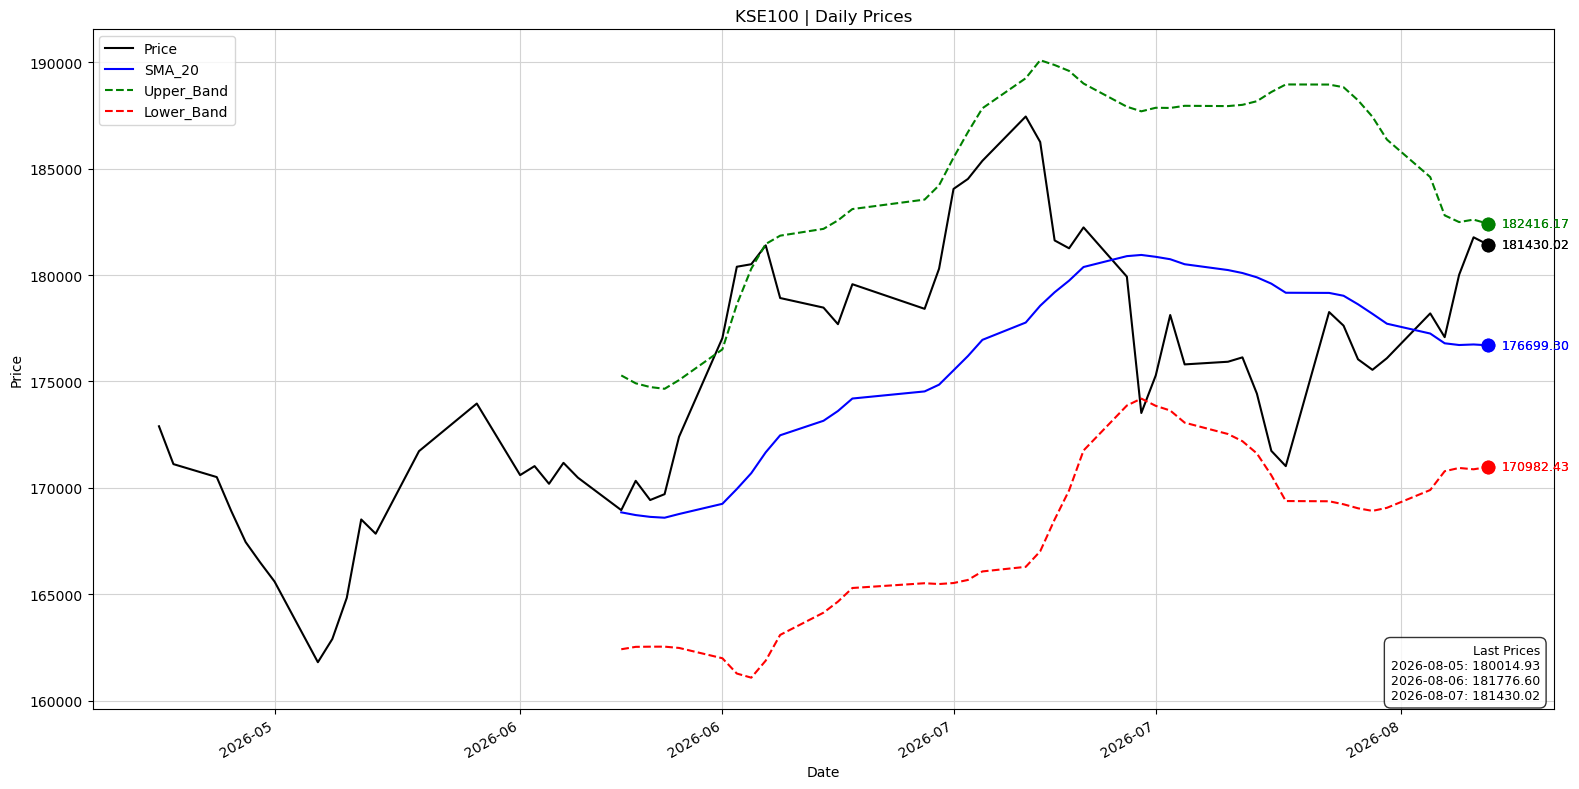

KMI30
Showing data from 2026-05-07 to 2026-08-07
✅ Plot saved to: D:\repos\PriceData\Exports\2026-08-09\KMI30-DAILY-QUARTER-2026-08-09.png


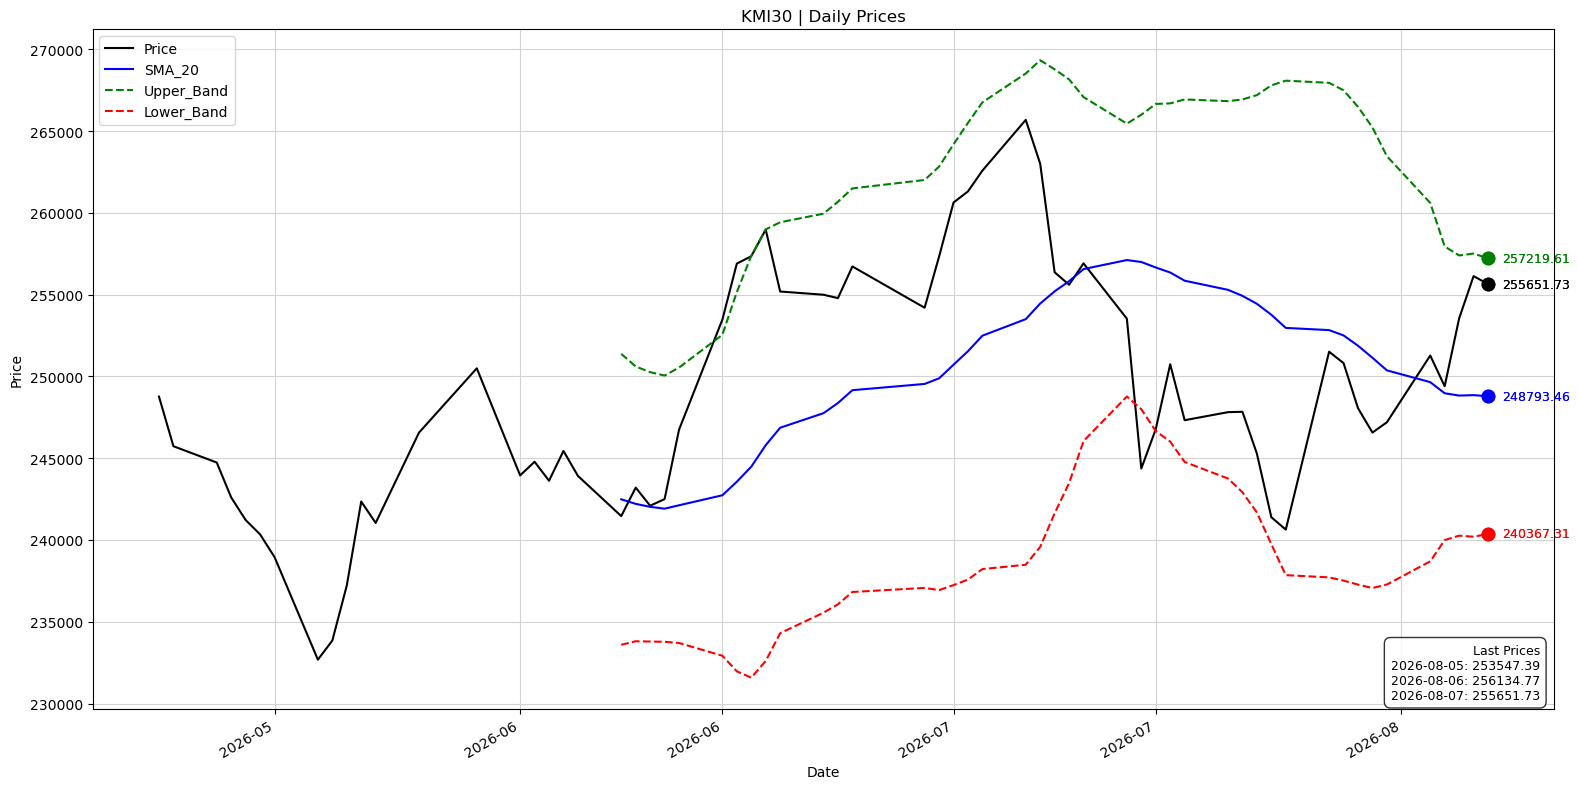

KMIF
Showing data from 2026-05-04 to 2026-08-04
✅ Plot saved to: D:\repos\PriceData\Exports\2026-08-09\KMIF-DAILY-QUARTER-2026-08-09.png


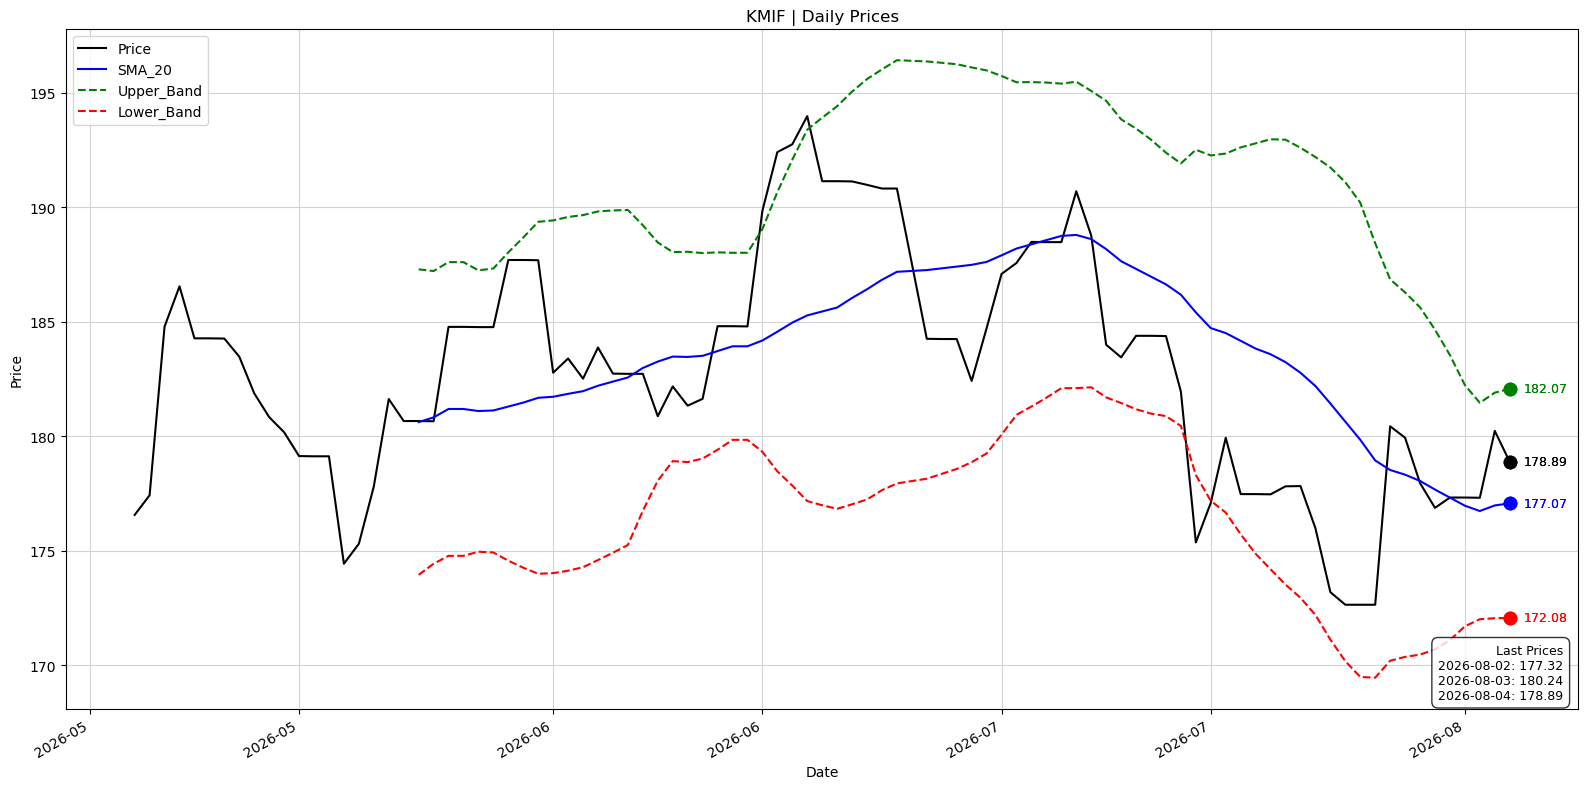

MIF
Showing data from 2026-05-03 to 2026-08-03
✅ Plot saved to: D:\repos\PriceData\Exports\2026-08-09\MIF-DAILY-QUARTER-2026-08-09.png


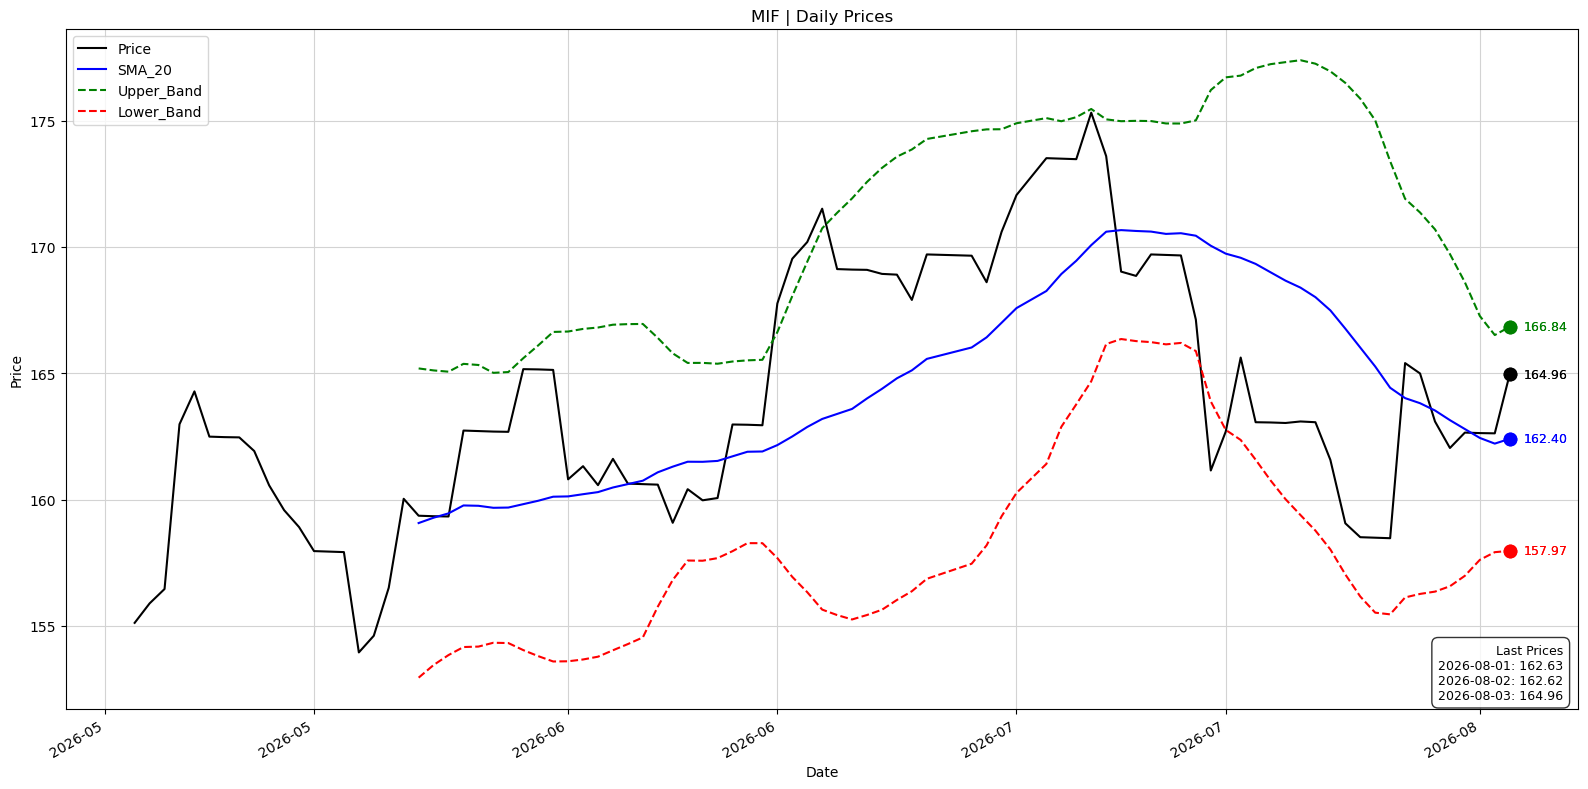

MBF
Showing data from 2026-05-03 to 2026-08-03
✅ Plot saved to: D:\repos\PriceData\Exports\2026-08-09\MBF-DAILY-QUARTER-2026-08-09.png


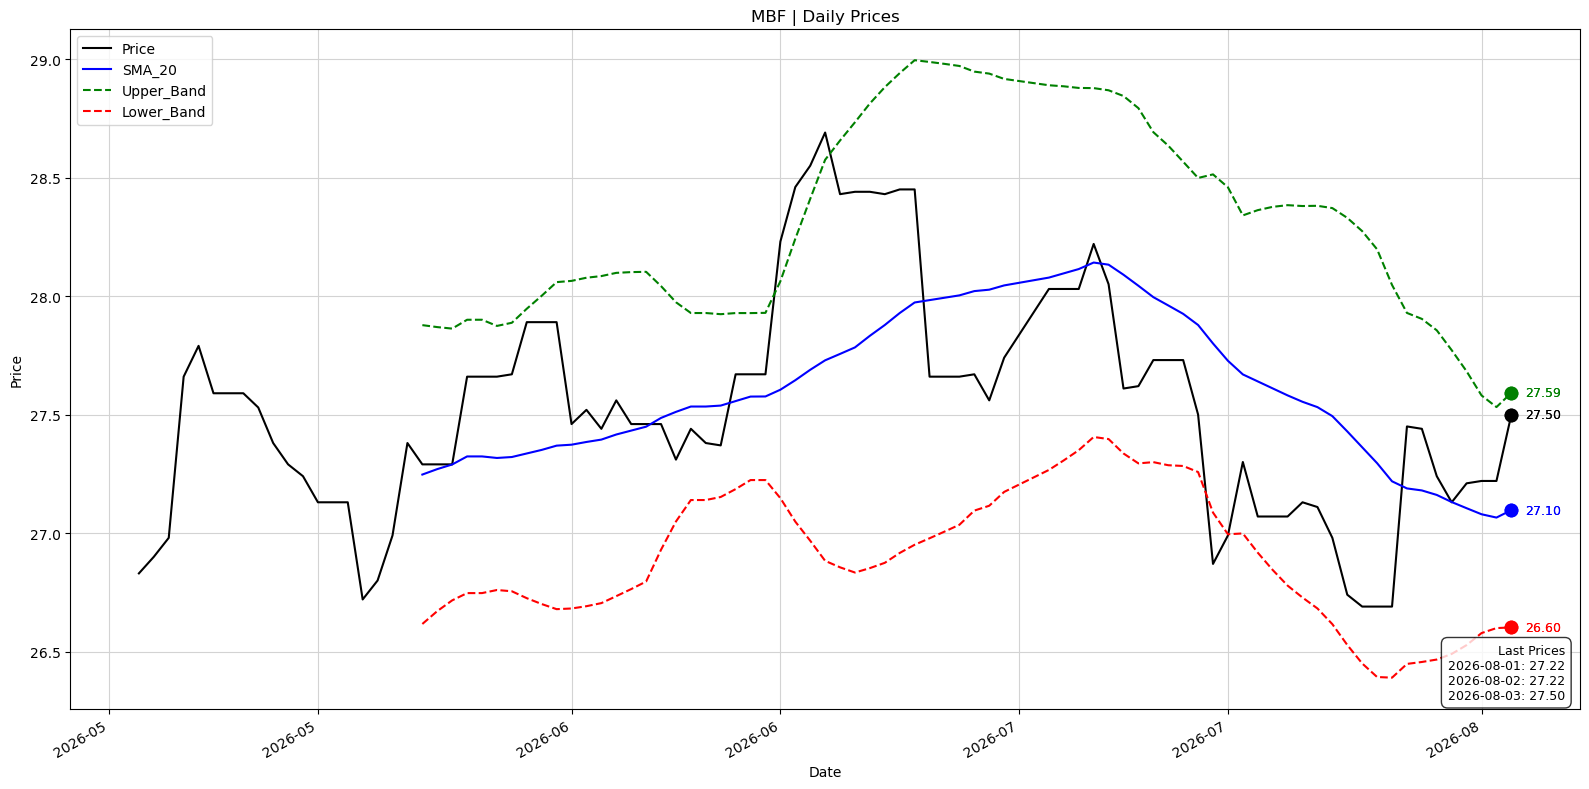

USDPKR
Showing data from 2026-05-07 to 2026-08-07
✅ Plot saved to: D:\repos\PriceData\Exports\2026-08-09\USDPKR-DAILY-QUARTER-2026-08-09.png


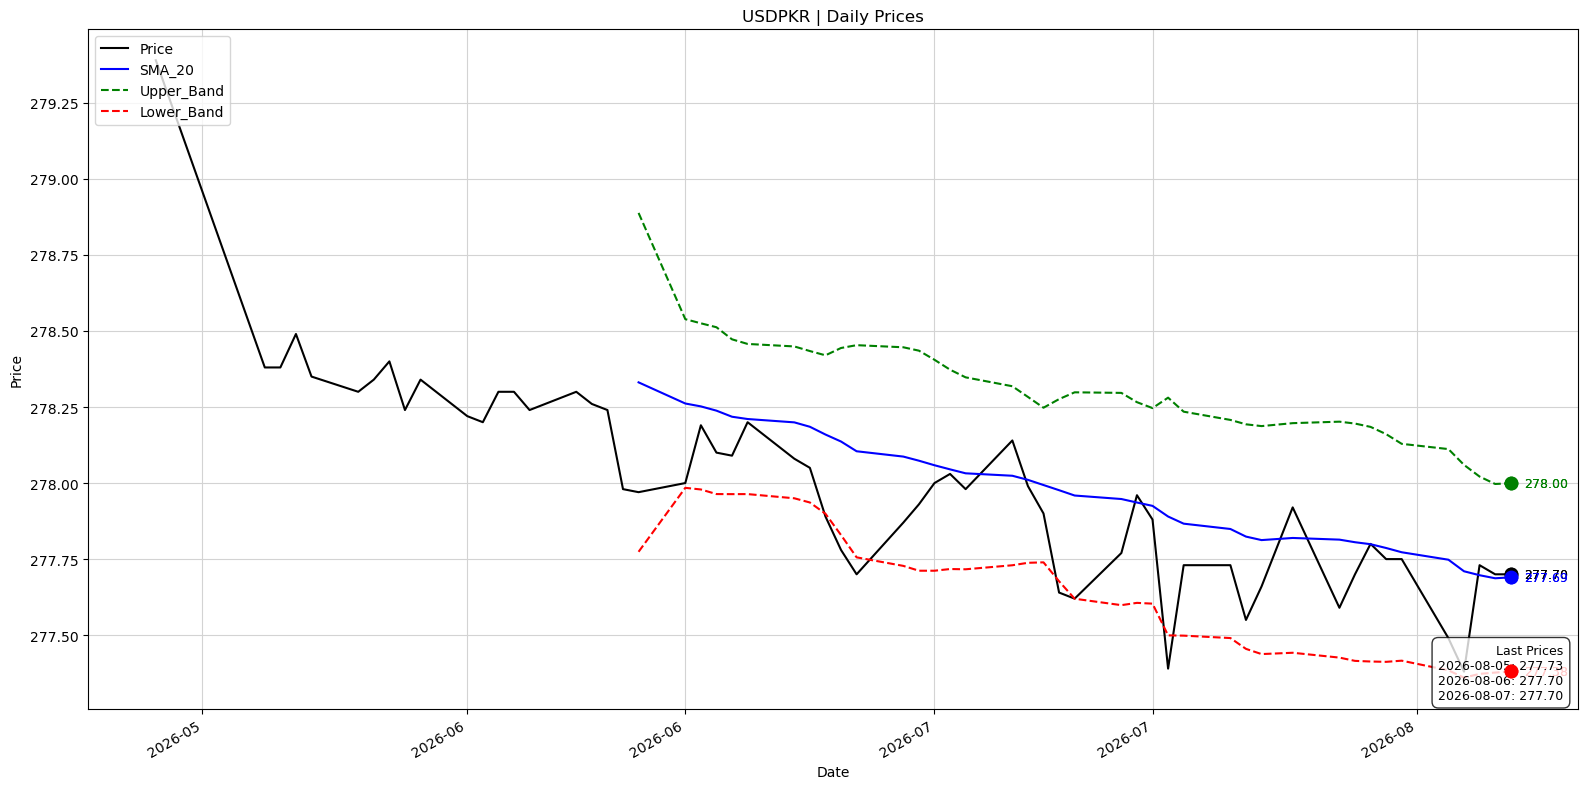

GOLDPK
Showing data from 2026-05-09 to 2026-08-09
✅ Plot saved to: D:\repos\PriceData\Exports\2026-08-09\GOLDPK-DAILY-QUARTER-2026-08-09.png


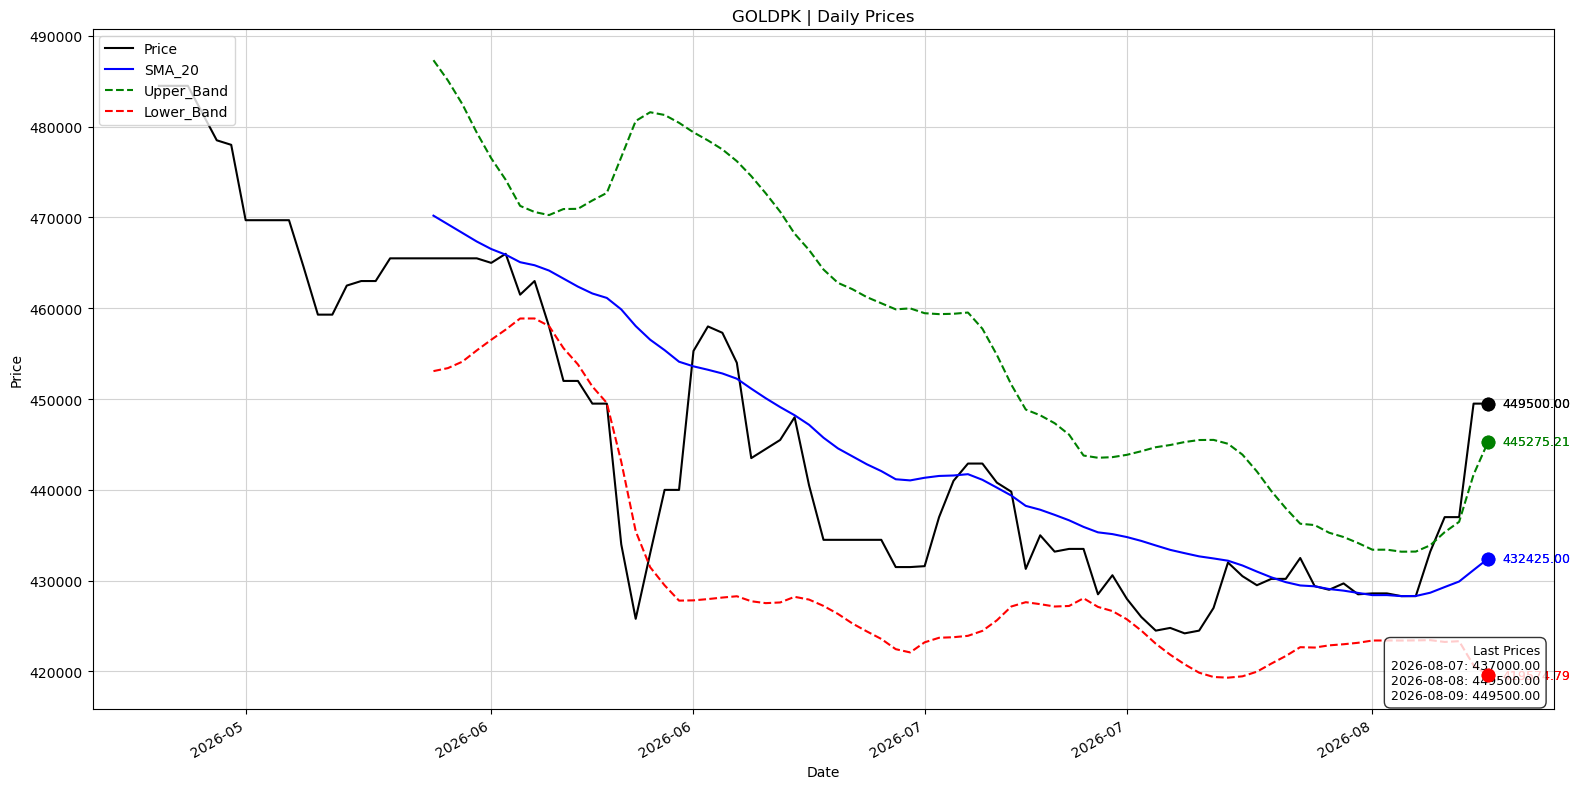

MGF
Showing data from 2026-05-03 to 2026-08-03
✅ Plot saved to: D:\repos\PriceData\Exports\2026-08-09\MGF-DAILY-QUARTER-2026-08-09.png


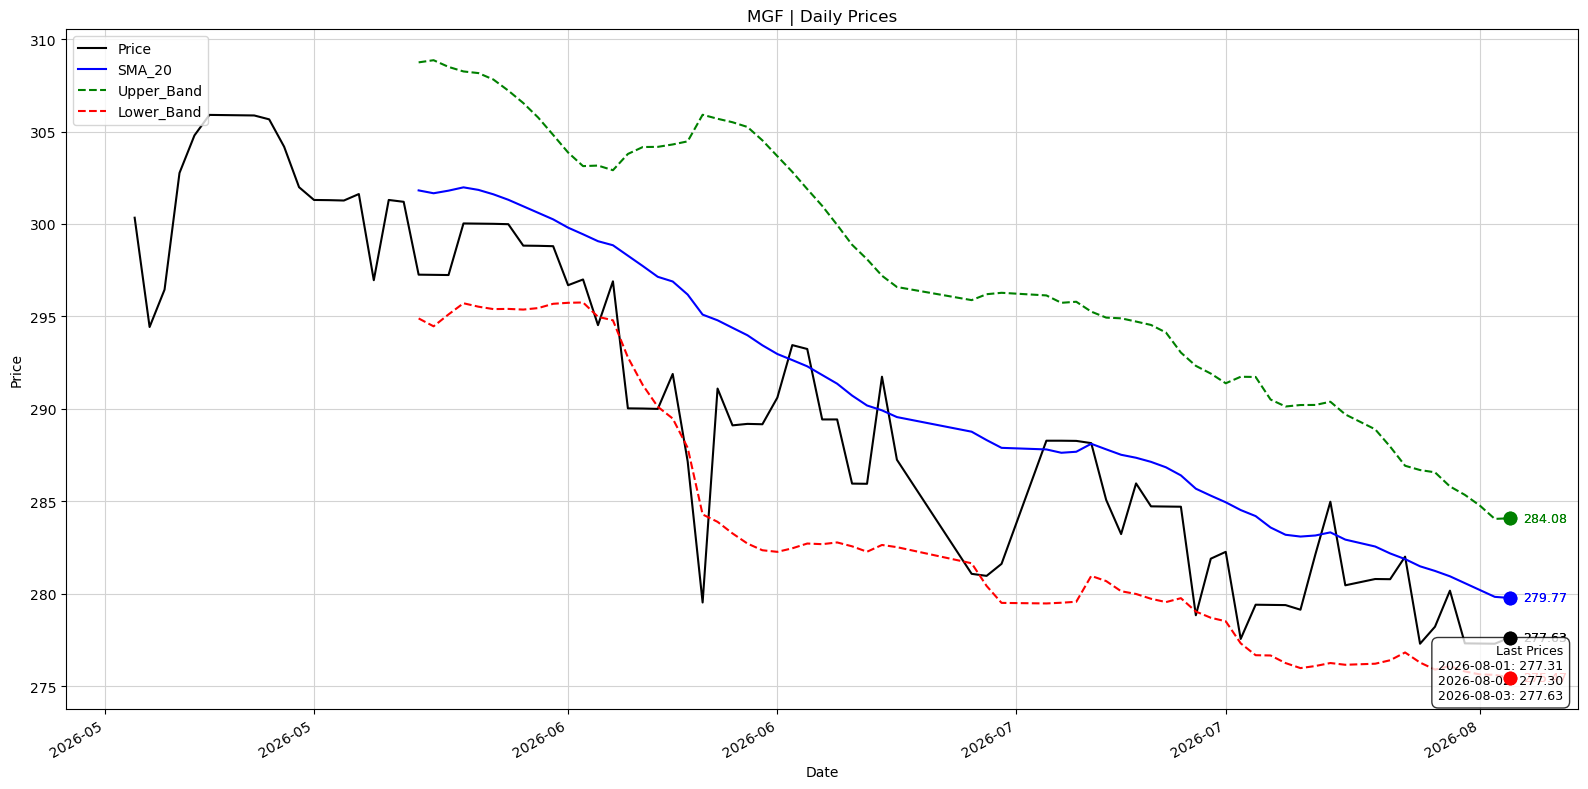

In [18]:
# === MAIN RUN ===
# if __name__ == "__main__":

interval, timeframe = "Daily", "Quarter"
#interval, timeframe = "Weekly", "Year"
#interval, timeframe = "Monthly", "All"
summary_records = []

for inst in INSTRUMENT_PATHS:
    df = process_instrument(inst, interval, timeframe)
    if df is not None and not df.empty:
        last_idx, last_row = df.index.max(), df.iloc[-1]
        summary_records.append({
            "Instrument": inst,
            "Date": last_idx,
            "Price": last_row.get("price"),
            "SMA_20": last_row.get("SMA_20"),
            "Upper_Band": last_row.get("Upper_Band"),
            "Lower_Band": last_row.get("Lower_Band"),
        })

In [19]:
summary_df = pd.DataFrame(summary_records).round(2)
if not summary_df.empty:
    summary_df["Date"] = pd.to_datetime(summary_df["Date"])
    summary_df = summary_df.sort_values("Date").reset_index(drop=True)

    print("\n📊 Final Summary:\n")
    print(summary_df)
    save_summary_table(summary_df, interval, timeframe)


📊 Final Summary:

  Instrument       Date      Price     SMA_20  Upper_Band  Lower_Band
0        MIF 2026-08-03     164.96     162.40      166.84      157.97
1        MBF 2026-08-03      27.50      27.10       27.59       26.60
2        MGF 2026-08-03     277.63     279.77      284.08      275.47
3       KMIF 2026-08-04     178.89     177.07      182.07      172.08
4     KSE100 2026-08-07  181430.02  176699.30   182416.17   170982.43
5      KMI30 2026-08-07  255651.73  248793.46   257219.61   240367.31
6     USDPKR 2026-08-07     277.70     277.69      278.00      277.38
7     GOLDPK 2026-08-09  449500.00  432425.00   445275.21   419574.79
✅ Plot saved to: D:\repos\PriceData\Exports\2026-08-09\SUMMARY-DAILY-QUARTER-2026-08-09.png
